In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## loss-landscape

**Training-loss landscape of ResNet-56 (5.89% test error) on CIFAR-10 around its trained minimizer, redrawn from Li et al. (2018), Figure 5(b).** The axes are the coefficients α and β of two filter-normalized random directions, labelled contours give the training loss, and the red circle marks the minimizer at (0, 0). With skip connections the minimizer sits in a wide, nearly convex basin: contours up to a loss of 3.1 are closed, roughly elliptical rings, and the loss stays below 1.1 within a distance of 0.4 of the minimizer.

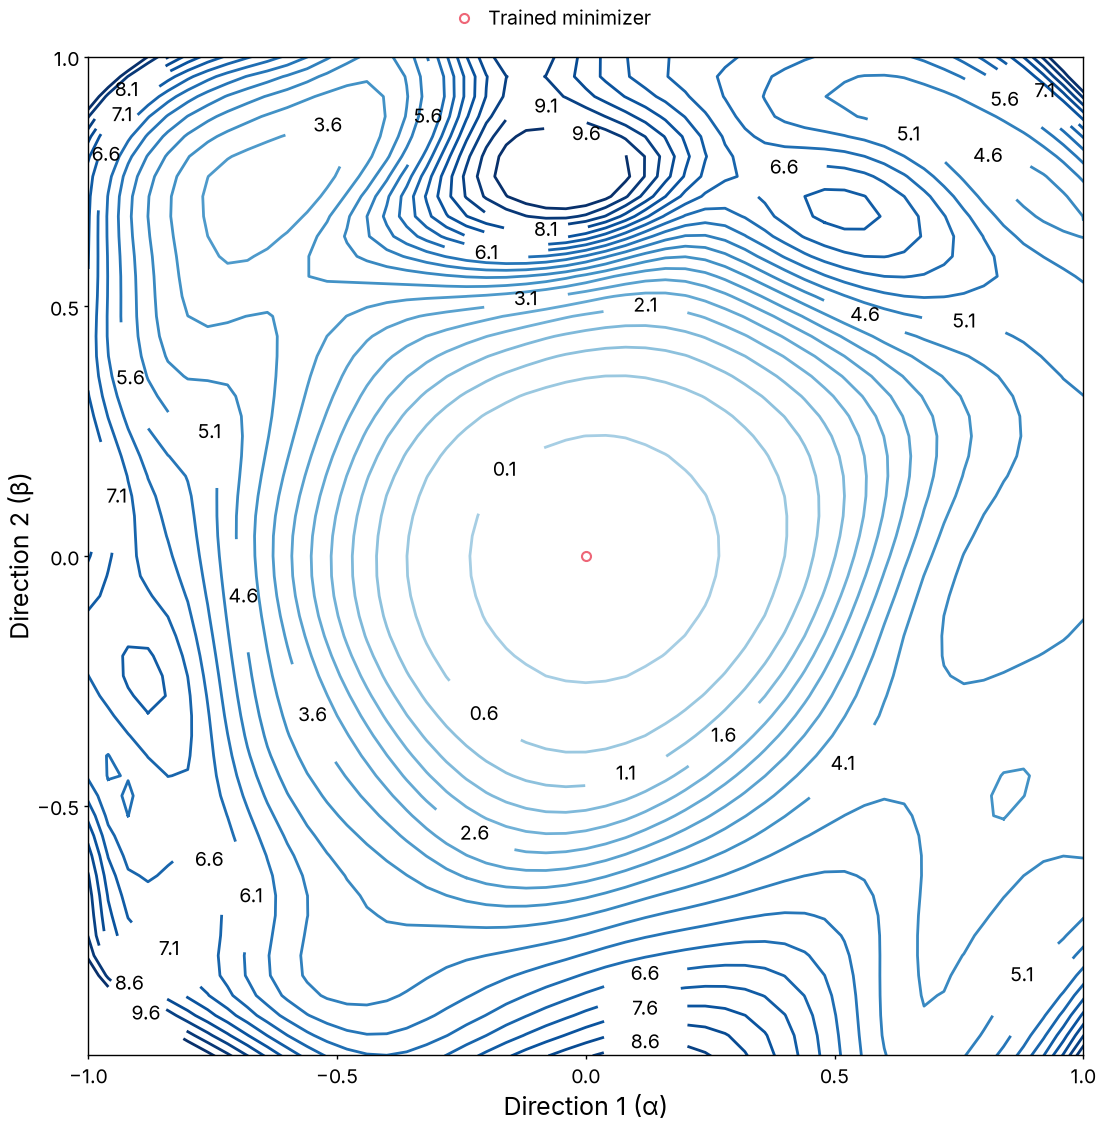

In [2]:
from matplotlib.colors import ListedColormap

with open("../loss-landscape.json") as f:
    data = json.load(f)

cmap = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.35, 1, 256)))
norm = plt.Normalize(min(data["levels"]), max(data["levels"]))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for line in data["contour_lines"]:
    x, y = np.array(line["xy"]).T
    ax.plot(x, y, color=cmap(norm(line["level"])), linewidth=plt.rcParams["contour.linewidth"])
# the paper's labels were placed for a smaller panel; skip those that would collide with one already drawn
placed = []
for label in data["level_labels"]:
    x, y = label["xy"]
    if all(abs(x - px) > 0.08 or abs(y - py) > 0.05 for px, py in placed):
        ax.text(x, y, f"{label['level']:.2g}", ha="center", va="center")
        placed.append((x, y))
ax.plot(0, 0, "o", color=colors["ours"], label="Trained minimizer")
ax.set_xlim(data["x_range"])
ax.set_ylim(data["y_range"])
ax.grid(False)
ax.set_xlabel("Direction 1 (α)")
ax.set_ylabel("Direction 2 (β)")
ax.set_xticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticks([-0.5, 0, 0.5, 1])
fig.legend(loc="outside upper center", frameon=False, borderaxespad=0)

fit_height(fig, ax, aspect=1.0)
fig.savefig("loss-landscape.pdf")
fig.savefig("loss-landscape.png")
plt.show()